# trialwarp tutorial: aligning noisy trials with time warping

Repeated trials of the same process rarely share exact timing. A neuron fires a little earlier on one trial and later on the next, and a movement unfolds faster on some repetitions than others. A **plain trial average** then smears every timing-locked feature into a low, wide bump.

`trialwarp` learns two things from the trials themselves:

* a shared **template**, the pattern every trial is a version of;
* one **warping function** per trial, `ω_k(t)`, a monotone, piecewise-linear map from the trial's clock to the template's clock.

The model is `X[k, t] ≈ template(ω_k(t))`. Once the warps are known, each trial can be resampled onto the template's clock, so the important timing patterns line up.

This notebook walks through fitting, aligning, inspecting the warps, applying them to other data, and checking that the warping is real and not fitted noise.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import trialwarp as tw
from trialwarp import plotting

%matplotlib inline

## 1. Data

trialwarp works on arrays shaped **(n_trials, n_timepoints, n_features)**. Features can be neurons, EMG channels, joint angles, or any other signals recorded on the same trials. A 2D array (n_trials, n_timepoints) is treated as a single feature.

Here we simulate 100 trials of a 10-dimensional signal. Each trial reads the same template through its own random one-knot warp and has Gaussian noise added. Because the data are synthetic, we also keep the ground truth.

In [2]:
data = tw.make_warped_trials(
    n_trials=100, n_timepoints=150, n_features=10, n_knots=1, noise=0.5, random_state=0
)
X = data.data
X.shape

(100, 150, 10)

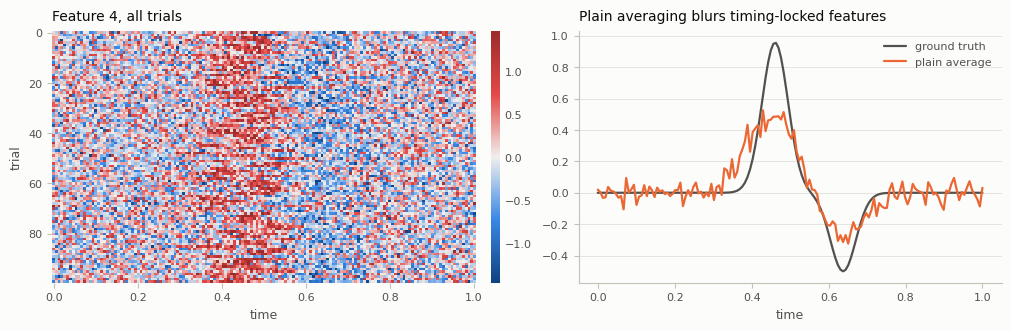

In [3]:
feature = 4
with plotting.style():
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout="constrained")
    plotting.plot_trials(X, feature=feature, ax=axes[0], title=f"Feature {feature}, all trials")
    axes[1].plot(
        data.time, data.template[:, feature], color=plotting.INK_SECONDARY, label="ground truth"
    )
    axes[1].plot(
        data.time,
        X[:, :, feature].mean(axis=0),
        color=plotting.COLORS["orange"],
        label="plain average",
    )
    axes[1].grid(axis="y")
    axes[1].legend()
    axes[1].set_title("Plain averaging blurs timing-locked features")
    axes[1].set_xlabel("time")

## 2. Fit a model

There are three model families:

| model | warp | use when |
|---|---|---|
| `ShiftWarping` | `ω(t) = t + shift` | trials differ by a delay only |
| `LinearWarping` | `ω(t) = a + b·t` | trials are also uniformly faster or slower |
| `PiecewiseWarping(n_knots=k)` | `k + 1` linear segments | different parts of a trial stretch differently |

A good habit is to fit a simple model first and use it to initialize a more flexible one.

In [4]:
linear = tw.LinearWarping(random_state=0).fit(X)
model = tw.PiecewiseWarping(n_knots=1, random_state=0).fit(X, init=linear)
model

PiecewiseWarping(n_knots=1, max_lag=0.3, max_stretch=3.0, warp_reg=1.0, smoothness=0.01, l2_reg=0.0, n_bins=None, random_state=0)

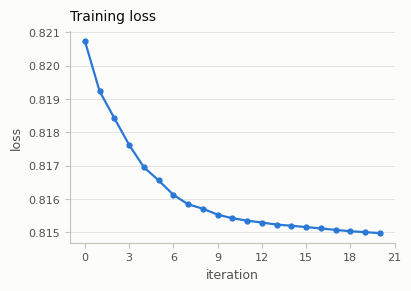

In [5]:
plotting.plot_loss(model);

## 3. Align the trials and compare with plain averaging

`transform` resamples every trial onto the template's clock. Samples that fall outside a trial's recorded window become NaN, so use `np.nanmean` to average.

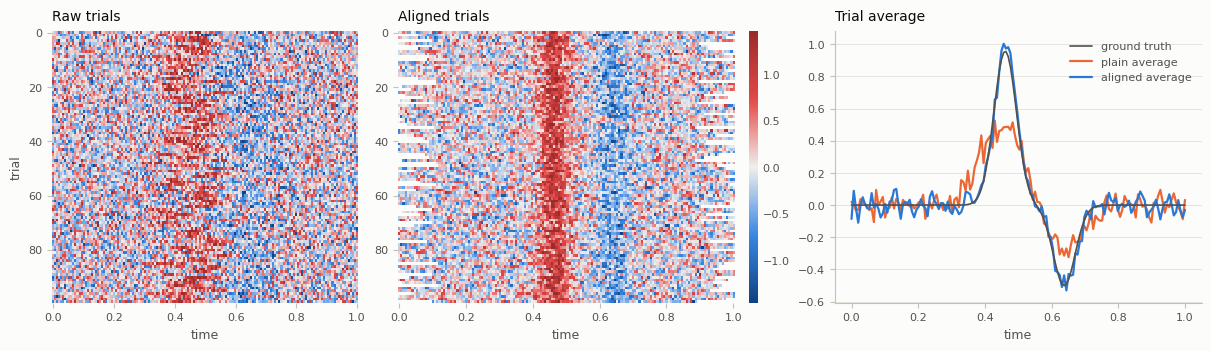

In [6]:
aligned = model.transform(X)
plotting.plot_alignment(X, aligned, feature=feature, truth=data.template);

In [7]:
def r_squared(estimate, truth):
    return 1 - np.sum((estimate - truth) ** 2) / np.sum((truth - truth.mean(axis=0)) ** 2)


estimates = {
    "plain average": X.mean(axis=0),
    "average of aligned trials": np.nanmean(aligned, axis=0),
    "model template": model.template_,
}
for name, estimate in estimates.items():
    print(f"{name:26s} R^2 = {r_squared(estimate, data.template):.3f}")

plain average              R^2 = 0.636
average of aligned trials  R^2 = 0.957
model template             R^2 = 0.985


## 4. Inspect the warps

`plot_warps` draws `ω_k(t) − t` for every trial: how far ahead of (> 0) or behind (< 0) the template each moment of the trial runs. A flat line is a pure shift and a tilted line is a uniform stretch; with `n_knots=1`, each warp bends once.

Because the synthetic data come with true warps, we can draw both. `make_warped_trials` returns an object with the same `warping_functions` method as a fitted model.

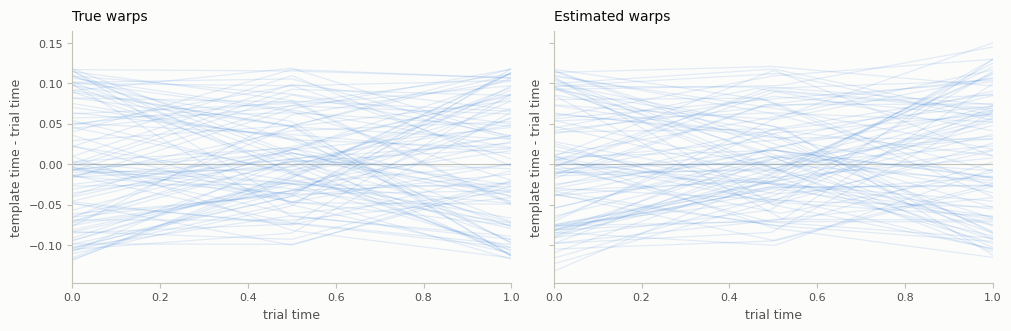

In [8]:
with plotting.style():
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True, layout="constrained")
plotting.plot_warps(data, ax=axes[0], title="True warps")
plotting.plot_warps(model, ax=axes[1], title="Estimated warps");

The fitted parameters live in `x_knots_` and `y_knots_`: knot times on the trial clock and on the template clock. `warping_functions(t)` evaluates every warp at any normalized times `t`.

In [9]:
print("knots of trial 0, trial clock:   ", np.round(model.x_knots_[0], 3))
print("knots of trial 0, template clock:", np.round(model.y_knots_[0], 3))

knots of trial 0, trial clock:    [0.  0.5 1. ]
knots of trial 0, template clock: [-0.039  0.484  1.008]


## 5. Apply the warps to other things

Warps are defined on **normalized time**, where 0 is the first sample and 1 is the last. So they can be applied to:

* **other signals recorded on the same trials**, such as raw (unsmoothed) data, other channels, or a different sampling rate: `model.transform(other)`;
* **event times**, such as spikes, licks or button presses: `model.transform_events(trials, times)`. With `tmin` and `tmax` (the times of the first and last sample), times can stay in seconds;
* **template moments mapped back onto each trial**: `model.inverse_transform_events(...)` gives each trial's time of, for example, the template's peak.

Let's find when each trial reaches the template's largest peak of feature 4.

In [10]:
trials = np.arange(len(X))
peak = data.time[np.argmax(model.template_[:, feature])]  # on the template clock
trial_times = model.inverse_transform_events(trials, np.full(len(X), peak))
print(
    f"template peak at t = {peak:.3f}; per-trial peak times range "
    f"{trial_times.min():.3f} to {trial_times.max():.3f}"
)

# the same in seconds, for a trial window recorded from -0.5 s to 1.0 s
in_seconds = model.inverse_transform_events(
    trials, np.full(len(X), -0.5 + 1.5 * peak), tmin=-0.5, tmax=1.0
)
print("first five trials (s):", np.round(in_seconds[:5], 3))

template peak at t = 0.463; per-trial peak times range 0.344 to 0.554
first five trials (s): [0.221 0.051 0.194 0.203 0.261]


## 6. Is the warping real?

Warping **always** lowers the training loss, even on pure noise, so the loss alone can't tell you whether trial-to-trial timing variability exists. `heldout_feature_score` runs a double cross-validation:

1. warps are fitted on all but one fold of the features;
2. for the held-out features, a template is fitted on all but one fold of the trials and must predict the remaining trials, read out through their warps;
3. the same prediction with identity warps is the baseline.

A consistently positive `improvement` means the warps generalize to data the model never saw. As a control, we run the same test on data from an identical generator with the warps switched off (`max_lag=0`).

In [11]:
null = tw.make_warped_trials(
    n_trials=100, n_timepoints=150, n_features=10, max_lag=0.0, noise=0.5, random_state=0
)
candidate = tw.PiecewiseWarping(n_knots=1, random_state=0)
print("warped data:", tw.heldout_feature_score(candidate, X, random_state=0))
print("null data:  ", tw.heldout_feature_score(candidate, null.data, random_state=0))

warped data: held-out R^2  unwarped 0.075 +/- 0.015  warped 0.181 +/- 0.018  improvement 0.106 +/- 0.008  (5 folds)


null data:   held-out R^2  unwarped 0.183 +/- 0.023  warped 0.181 +/- 0.022  improvement -0.002 +/- 0.001  (5 folds)


## 7. Tips for your own data

* **Shape and units.** Put trials on a common window, shaped (n_trials, n_timepoints, n_features). Pad shorter trials with NaN; missing values are ignored by the fit.
* **Scale.** The fit weights every feature by its variance. If features have very different scales (for example, firing rates of 1 Hz and 80 Hz), consider z-scoring or square-root transforming them first.
* **Spikes.** Bin with `tw.bin_spikes`, smooth with `tw.smooth_trials`, fit on the smoothed rates, and warp the raw spike times with `transform_events` (see `02_neural_spikes.py`).
* **Choosing a model.** Start with `ShiftWarping` or `LinearWarping`, then try `PiecewiseWarping` with 1 or 2 knots, initialized from the simpler fit. Keep the most flexible model that still improves `heldout_feature_score`.
* **Regularization.**
  * `warp_reg` (default 1) pulls warps toward the identity; raise it if the validation gain is small or negative.
  * `max_lag` and `max_stretch` are hard limits on displacement and local stretch.
  * `smoothness` sets the template's smoothing timescale as a fraction of the trial.
* **Speed.** The cost grows with trials × timepoints × features. With many features (more than template samples), the warp search runs in the template's principal subspace automatically. To trade a little accuracy for speed, lower `n_iter`, `n_proposals` or `n_candidates` in `fit`.